# Data Preprocessing + Initial EDA (Milestone 1)

This notebook covers data cleaning, schema/relationships, initial exploratory analysis, and data gaps/proxy measures for BU CCD Handshake employer engagement data (Spring 2020–Summer 2025).

**Contributors:** Shaotai Hu (cleaning + schema); Abigail Merage (EDA + milestone write-up integration)

Documentation link https://docs.google.com/document/d/1vURMI1VaFVwlVZkdtHFTEj1ys6Bwc0y1Oz1i5GJ8c_Q/edit?usp=sharing


In [1]:
# =========================
# Setup
# =========================
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# ---- File locations ----
# Update DATA_DIR to wherever your CSVs live.
DATA_DIR = "."

EMPLOYER_BASE_FILE = "Employer Base Dataset (Spring 2020 - Summer 2025).csv"
EMPLOYER_EVENT_FILE = "Employer Event Dataset (Spring 2020 - Summer 2025).csv"
EMPLOYER_JOB_FILE  = "Employer Job Dataset (Spring 2020 - Summer 2025).csv"

ep_base  = pd.read_csv(os.path.join(DATA_DIR, EMPLOYER_BASE_FILE))
ep_event = pd.read_csv(os.path.join(DATA_DIR, EMPLOYER_EVENT_FILE))
ep_job   = pd.read_csv(os.path.join(DATA_DIR, EMPLOYER_JOB_FILE))

print("Raw shapes:")
print("ep_base :", ep_base.shape)
print("ep_event:", ep_event.shape)
print("ep_job  :", ep_job.shape)


Raw shapes:
ep_base : (56089, 9)
ep_event: (12318, 7)
ep_job  : (886840, 8)


## 1) General cleaning (all datasets)

- Standardize column names
- Align primary key name (`employer_id`)
- Lowercase string columns (for consistent matching)
- Drop fully empty rows


In [2]:
# =========================
# General cleaning (all datasets)
# =========================

# Standardize column names
for df in (ep_base, ep_event, ep_job):
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Match primary key / ID naming
ep_base  = ep_base.rename(columns={"id": "employer_id"})
ep_event = ep_event.rename(columns={"employers_id": "employer_id"})
# ep_job already uses employer_id in the cleaned export; no-op if present

# Lowercase all string values (string columns only)
for df in (ep_base, ep_event, ep_job):
    str_cols = df.select_dtypes(include="object").columns
    df[str_cols] = df[str_cols].apply(lambda s: s.str.lower())

# Drop fully empty rows
ep_base  = ep_base.replace(r"^\s*$", np.nan, regex=True).dropna(how="all")
ep_event = ep_event.replace(r"^\s*$", np.nan, regex=True).dropna(how="all")
ep_job   = ep_job.replace(r"^\s*$", np.nan, regex=True).dropna(how="all")


## 2) Employer base cleaning

- Drop duplicate employers
- Drop meaningless CSV-export columns (e.g., `unnamed:*`, `count`)
- Create numeric employer size min/max
- Parse employer creation date


In [5]:
# =========================
# Employer base cleaning
# =========================

# Drop duplicates
ep_base = ep_base.drop_duplicates(subset="employer_id")

# Drop meaningless columns safely
cols_to_drop = [c for c in ep_base.columns if c.startswith("unnamed")]
if "count" in ep_base.columns:
    cols_to_drop.append("count")
if cols_to_drop:
    ep_base = ep_base.drop(columns=cols_to_drop)

# Rename to employer type (handle a couple common variants)
if "name.1" in ep_base.columns:
    ep_base = ep_base.rename(columns={"name.1": "employer_type"})
elif "name_1" in ep_base.columns:
    ep_base = ep_base.rename(columns={"name_1": "employer_type"})

# Split employer_size into min/max (if present)
if "employer_size" in ep_base.columns:
    size_split = ep_base["employer_size"].astype(str).str.split(" - ", n=1, expand=True)
    ep_base["employer_size_min"] = pd.to_numeric(size_split[0], errors="coerce")
    ep_base["employer_size_max"] = pd.to_numeric(size_split[1] if size_split.shape[1] > 1 else np.nan, errors="coerce")
    ep_base = ep_base.drop(columns=["employer_size"])

# Date parsing (handle either created_at_date or created_at)
date_col = None
if "created_at_date" in ep_base.columns:
    date_col = "created_at_date"
elif "created_at" in ep_base.columns:
    date_col = "created_at"

if date_col:
    ep_base[date_col] = pd.to_datetime(ep_base[date_col], errors="coerce")
    ep_base = ep_base.rename(columns={date_col: "employer_creation_date"})

ep_base.head()


,name,employer_id,employer_type,employer_creation_date,email,website,employer_size_min,employer_size_max
0,"lawhon & associates, inc.",392601,environmental services,2019-02-05,kblitzer@lawhon-assoc.com,http://www.lawhon-assoc.com,10.0,50.0
1,modulus global inc.,385582,management consulting,2019-01-18,jeff@modulus.io,https://www.modulusglobal.com/,1.0,10.0
2,chameleon coffee,1008255,food & beverage,2025-01-13,careers@chameleoncoffee.com,https://www.chameleoncoffee.com,100.0,250.0
3,brookstone management concepts,422901,"advertising, pr & marketing",2019-04-18,hr@brookstonemgmtconcepts.com,https://brookstonemgmtconcepts.com/,50.0,100.0
4,department 13,252845,electronic & computer hardware,2018-02-21,hr@department13.com,http://department13.com,10.0,50.0


## 3) Employer event cleaning

- Drop duplicate events
- Ensure attendance is numeric
- Rename date + medium fields
- Parse event date


In [6]:
# =========================
# Employer event cleaning
# =========================

ep_event = ep_event.drop_duplicates(subset="events_id")

# Student attendance count as numeric
if "student_attendees_count" in ep_event.columns:
    ep_event["student_attendees_count"] = pd.to_numeric(ep_event["student_attendees_count"], errors="coerce").fillna(0)

# Rename fields (if needed)
ep_event = ep_event.rename(columns={
    "events_start_date_date": "event_date",
    "event_medium_name": "event_medium"
})

# Date parsing
ep_event["event_date"] = pd.to_datetime(ep_event["event_date"], errors="coerce")

ep_event.head()


,events_name,event_date,events_id,employers_name,employer_id,event_medium,student_attendees_count
0,chat & connect: explore behavior technician jo...,2025-08-27,1801479,autism learning partners,72869,virtual,0
1,sevita virtual hiring event- connect. explore....,2025-08-26,1796898,sevita,59790,hybrid,0
2,go beyond the classroom: educational consultin...,2025-08-29,1794932,cardinal education,17654,virtual,1
3,amazon 2025 warehouse virtual information sess...,2025-08-21,1793355,amazon,22003,virtual,3
4,explore your future with viridien: student inf...,2025-08-19,1792463,viridien,35449,virtual,6


## 4) Employer job cleaning

- Drop duplicate job postings
- Rename date + salary fields
- Standardize salary to numeric (note: salary units appear mixed; see Data Gaps section)
- Parse job creation date


In [7]:
# =========================
# Employer job cleaning
# =========================

ep_job = ep_job.drop_duplicates(subset="jobs_id")

# Rename fields (if needed)
ep_job = ep_job.rename(columns={
    "jobs_created_at_date": "job_creation_date",
    "job_salaries_min_salary_in_dollars": "min_salary",
    "job_salaries_max_salary_in_dollars": "max_salary",
    "applications": "applications_count",
    "applications_count": "applications_count"  # keep if already correct
})

# Salary to numeric (robust to str or numeric)
for col in ("min_salary", "max_salary"):
    if col in ep_job.columns:
        ep_job[col] = (
            ep_job[col]
            .astype(str)
            .str.replace(",", "", regex=False)
            .replace({"nan": np.nan})
        )
        ep_job[col] = pd.to_numeric(ep_job[col], errors="coerce").fillna(0.0)

# Date parsing
ep_job["job_creation_date"] = pd.to_datetime(ep_job["job_creation_date"], errors="coerce")

ep_job.head()


,employer_name,employer_id,min_salary,max_salary,job_creation_date,jobs_title,jobs_id,applications_count
0,alumboost,1061634,50.0,50.0,2025-08-30,pre-med and pre-law tutor (remote),10231126,0
1,natural masters by new beginnings,1061534,0.0,0.0,2025-08-29,marketing coordinator,10228882,1
2,natural masters by new beginnings,1061534,0.0,0.0,2025-08-29,sales associate,10228857,0
3,sarpel household,1061467,30.0,40.0,2025-08-29,"morning routine coach (10+ hours), cambridge, ma",10227979,0
4,seven muses media llc,1061309,20.0,30.0,2025-08-28,crowdfunding assistance for record label / boo...,10221579,1


# EDA (Milestone 1)

dataset overview, high-level trends, engagement distributions, and documentation of limitations/proxies.


In [8]:
# =========================
# Dataset Overview
# =========================

print("Number of Employers (Base):", ep_base["employer_id"].nunique())

print("Number of Job Records:", len(ep_job))
print("Unique Employers in Jobs:", ep_job["employer_id"].nunique())

print("Number of Event Records:", len(ep_event))
print("Unique Employers in Events:", ep_event["employer_id"].nunique())

print("\nJob Date Range:", ep_job["job_creation_date"].min(), "to", ep_job["job_creation_date"].max())
print("Event Date Range:", ep_event["event_date"].min(), "to", ep_event["event_date"].max())

# Year columns for trend summaries
ep_job["year"] = ep_job["job_creation_date"].dt.year
ep_event["year"] = ep_event["event_date"].dt.year

jobs_per_year = ep_job.groupby("year").size()
events_per_year = ep_event.groupby("year").size()

print("\nJobs Per Year:\n", jobs_per_year)
print("\nEvents Per Year:\n", events_per_year)

print("\nPercent of employers in base that post jobs:",
      round((ep_job["employer_id"].nunique() / ep_base["employer_id"].nunique()) * 100, 2), "%")
print("Percent of employers in base that host events:",
      round((ep_event["employer_id"].nunique() / ep_base["employer_id"].nunique()) * 100, 2), "%")

job_employers = set(ep_job["employer_id"].unique())
event_employers = set(ep_event["employer_id"].unique())
both = job_employers.intersection(event_employers)
print("Percent of job-posting employers that also host events:",
      round((len(both) / len(job_employers)) * 100, 2), "%")


Number of Employers (Base): 56089
Number of Job Records: 886840
Unique Employers in Jobs: 48061
Number of Event Records: 11814
Unique Employers in Events: 1380

Job Date Range: 2020-01-01 00:00:00 to 2025-08-31 00:00:00
Event Date Range: 2020-01-01 00:00:00 to 2025-08-29 00:00:00

Jobs Per Year:
 year
2020     73314
2021    141202
2022    188768
2023    166995
2024    198453
2025    118108
dtype: int64

Events Per Year:
 year
2020    1122
2021    1956
2022    2455
2023    2597
2024    2520
2025    1164
dtype: int64

Percent of employers in base that post jobs: 85.69 %
Percent of employers in base that host events: 2.46 %
Percent of job-posting employers that also host events: 2.69 %


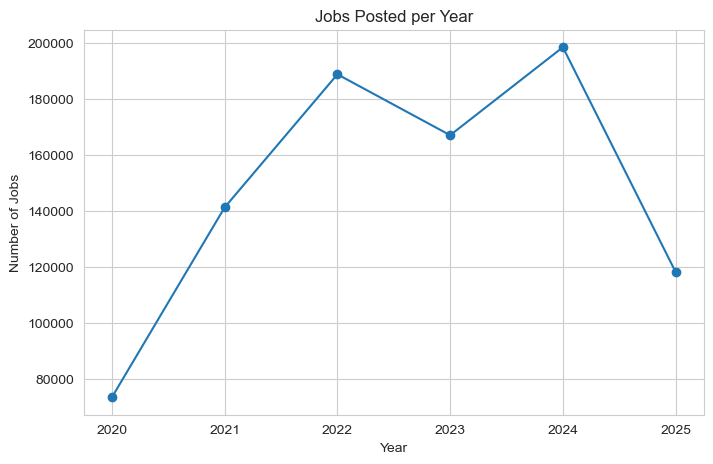

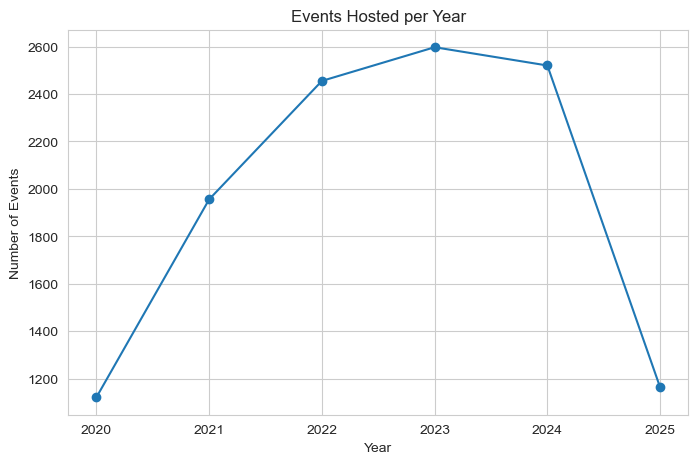

In [9]:
# =========================
# Trends over time (Yearly)
# =========================

plt.figure(figsize=(8,5))
jobs_per_year.plot(marker="o")
plt.title("Jobs Posted per Year")
plt.ylabel("Number of Jobs")
plt.xlabel("Year")
plt.show()

plt.figure(figsize=(8,5))
events_per_year.plot(marker="o")
plt.title("Events Hosted per Year")
plt.ylabel("Number of Events")
plt.xlabel("Year")
plt.show()


0         661973
1–5       164899
6–20       42092
21–100     16310
100+        1566
Name: app_bucket, dtype: int64


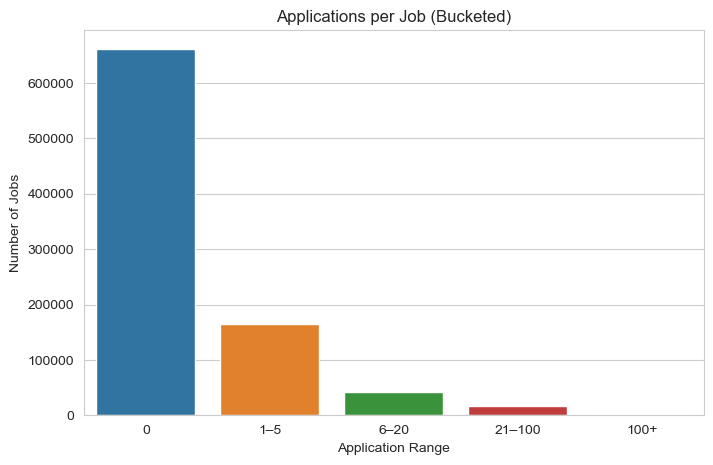

Percent of jobs with 0 applications: 74.64 %


In [10]:
# =========================
# Student interest (Applications per Job) - Bucketed
# =========================

def app_bucket(x):
    if x == 0:
        return "0"
    elif x <= 5:
        return "1–5"
    elif x <= 20:
        return "6–20"
    elif x <= 100:
        return "21–100"
    else:
        return "100+"

ep_job["applications_count"] = pd.to_numeric(ep_job["applications_count"], errors="coerce").fillna(0).astype(int)
ep_job["app_bucket"] = ep_job["applications_count"].apply(app_bucket)

bucket_order = ["0", "1–5", "6–20", "21–100", "100+"]

bucket_counts = ep_job["app_bucket"].value_counts().reindex(bucket_order)

print(bucket_counts)

plt.figure(figsize=(8,5))
sns.barplot(x=bucket_counts.index, y=bucket_counts.values)
plt.title("Applications per Job (Bucketed)")
plt.xlabel("Application Range")
plt.ylabel("Number of Jobs")
plt.show()

print("Percent of jobs with 0 applications:",
      round((ep_job["applications_count"] == 0).mean() * 100, 2), "%")


0         4336
1–10      5968
11–50     1267
51–100     154
100+        89
Name: attendance_bucket, dtype: int64


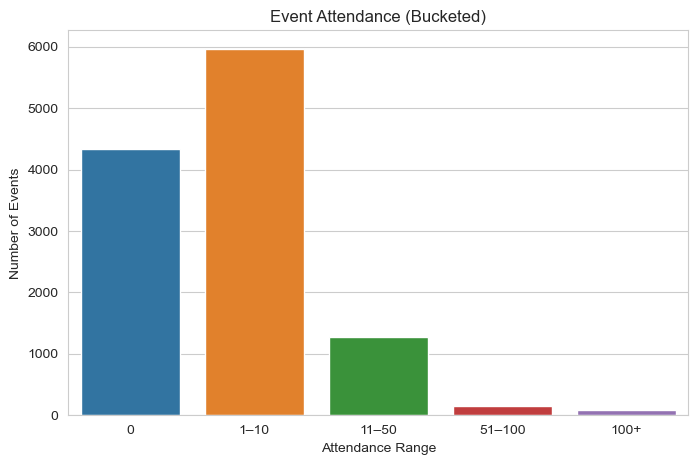

Percent of events with 0 attendees: 36.7 %


In [11]:
# =========================
# Student interest (Event Attendance) - Bucketed
# =========================

ep_event["student_attendees_count"] = pd.to_numeric(ep_event["student_attendees_count"], errors="coerce").fillna(0).astype(int)

def attendance_bucket(x):
    if x == 0:
        return "0"
    elif x <= 10:
        return "1–10"
    elif x <= 50:
        return "11–50"
    elif x <= 100:
        return "51–100"
    else:
        return "100+"

ep_event["attendance_bucket"] = ep_event["student_attendees_count"].apply(attendance_bucket)

att_order = ["0", "1–10", "11–50", "51–100", "100+"]
attendance_counts = ep_event["attendance_bucket"].value_counts().reindex(att_order)

print(attendance_counts)

plt.figure(figsize=(8,5))
sns.barplot(x=attendance_counts.index, y=attendance_counts.values)
plt.title("Event Attendance (Bucketed)")
plt.xlabel("Attendance Range")
plt.ylabel("Number of Events")
plt.show()

print("Percent of events with 0 attendees:",
      round((ep_event["student_attendees_count"] == 0).mean() * 100, 2), "%")


Event medium counts:
 virtual      10853
in-person      927
hybrid          34
Name: event_medium, dtype: int64


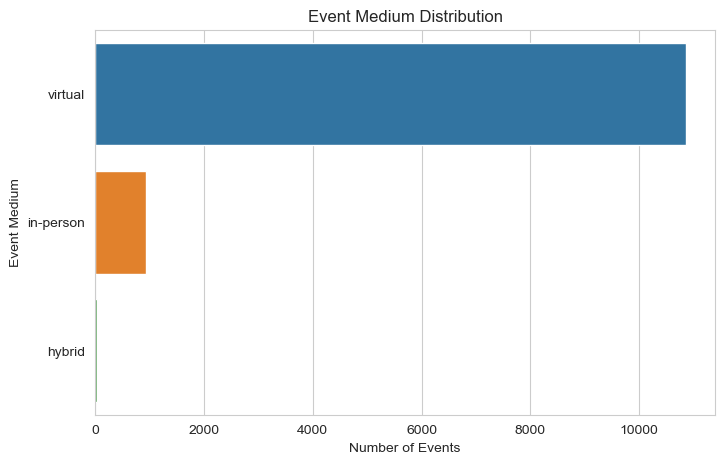


Average attendance by medium:
 event_medium
hybrid       35.000000
in-person    26.597627
virtual       4.181517
Name: student_attendees_count, dtype: float64


In [12]:
# =========================
# Event behavior: medium distribution + average attendance
# =========================

medium_counts = ep_event["event_medium"].value_counts()
print("Event medium counts:\n", medium_counts)

plt.figure(figsize=(8,5))
sns.barplot(x=medium_counts.values, y=medium_counts.index)
plt.title("Event Medium Distribution")
plt.xlabel("Number of Events")
plt.ylabel("Event Medium")
plt.show()

attendance_by_medium = (
    ep_event.groupby("event_medium")["student_attendees_count"]
    .mean()
    .sort_values(ascending=False)
)
print("\nAverage attendance by medium:\n", attendance_by_medium)


In [13]:
# =========================
# Employer-level summaries (avoid cartesian expansion from joining jobs x events)
# =========================

# Jobs summary per employer
employer_job_summary = (
    ep_job.groupby("employer_id")
    .agg(
        total_jobs=("jobs_id", "count"),
        total_applications=("applications_count", "sum"),
        avg_applications_per_job=("applications_count", "mean"),
        first_job_date=("job_creation_date", "min"),
        last_job_date=("job_creation_date", "max"),
    )
    .reset_index()
)

# Events summary per employer
employer_event_summary = (
    ep_event.groupby("employer_id")
    .agg(
        total_events=("events_id", "count"),
        total_attendance=("student_attendees_count", "sum"),
        avg_attendance_per_event=("student_attendees_count", "mean"),
    )
    .reset_index()
)

# Merge onto employer base for segmentation
employer_summary = (
    ep_base[["employer_id"]]
    .merge(employer_job_summary, on="employer_id", how="left")
    .merge(employer_event_summary, on="employer_id", how="left")
)

for col in ["total_jobs","total_applications","avg_applications_per_job","total_events","total_attendance","avg_attendance_per_event"]:
    employer_summary[col] = employer_summary[col].fillna(0)

employer_summary.head()


,employer_id,total_jobs,total_applications,avg_applications_per_job,first_job_date,last_job_date,total_events,total_attendance,avg_attendance_per_event
0,392601,5.0,1.0,0.2,2023-10-30,2025-02-06,0.0,0.0,0.0
1,385582,1.0,0.0,0.0,2023-12-30,2023-12-30,0.0,0.0,0.0
2,1008255,1.0,3.0,3.0,2025-01-14,2025-01-14,0.0,0.0,0.0
3,422901,0.0,0.0,0.0,NaT,NaT,0.0,0.0,0.0
4,252845,0.0,0.0,0.0,NaT,NaT,0.0,0.0,0.0


In [14]:
# =========================
# Job posting concentration (employer-level)
# =========================

single_job_pct = ((employer_job_summary["total_jobs"] == 1).mean() * 100)
print("Percent of employers posting only 1 job:", round(single_job_pct, 2), "%")

sorted_jobs = employer_job_summary.sort_values("total_jobs", ascending=False)
top_10pct_cutoff = int(len(sorted_jobs) * 0.10)

top_10pct_jobs = sorted_jobs.iloc[:top_10pct_cutoff]["total_jobs"].sum()
total_jobs_all = sorted_jobs["total_jobs"].sum()

print("Top 10% of employers account for:",
      round((top_10pct_jobs / total_jobs_all) * 100, 2), "% of all jobs")


Percent of employers posting only 1 job: 30.77 %
Top 10% of employers account for: 74.19 % of all jobs


Jobs Only        31043
No Activity      24111
Jobs + Events      886
Events Only         49
Name: engagement_type, dtype: int64


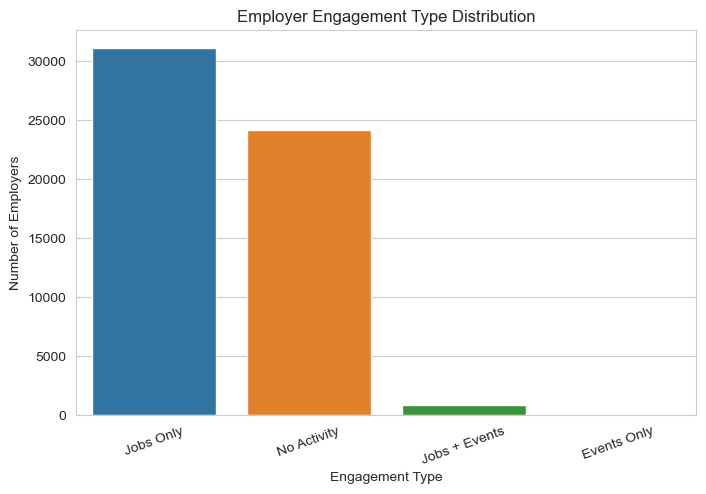

In [15]:
# =========================
# Employer engagement type segmentation
# =========================

def engagement_type(row):
    if row["total_jobs"] == 0 and row["total_events"] == 0:
        return "No Activity"
    elif row["total_jobs"] > 0 and row["total_events"] == 0:
        return "Jobs Only"
    elif row["total_jobs"] == 0 and row["total_events"] > 0:
        return "Events Only"
    else:
        return "Jobs + Events"

employer_summary["engagement_type"] = employer_summary.apply(engagement_type, axis=1)

engagement_counts = employer_summary["engagement_type"].value_counts()
print(engagement_counts)

plt.figure(figsize=(8,5))
sns.barplot(x=engagement_counts.index, y=engagement_counts.values)
plt.title("Employer Engagement Type Distribution")
plt.ylabel("Number of Employers")
plt.xlabel("Engagement Type")
plt.xticks(rotation=20)
plt.show()


In [16]:
# =========================
# Job title frequency (no structured job-type field available)
# =========================

top_titles = ep_job["jobs_title"].value_counts().head(20)
print(top_titles)


registered behavior technician (rbt) - growth opportunities!    4038
physical therapist                                              2579
marketing intern                                                1231
special education teacher                                       1177
staff accountant                                                1130
administrative assistant                                        1042
entry level outside sales trainee                               1019
registered nurse                                                 998
occupational therapist                                           887
software engineer                                                876
sales development representative                                 839
entry level advertising account manager trainee                  779
business development representative                              746
speech language pathologist                                      730
social media intern               

## Data gaps and proxy measures (Milestone 1)

**Observed gaps / limitations**
- No student-level attributes (only aggregate application counts and event attendance counts)
- No hiring outcomes (offers/acceptances/hires not present in these datasets)
- No structured job type / industry fields (job titles are free text)
- 2025 is partial-year in this export (data ends in Aug 2025)
- Off-platform engagement is not captured (applications and attendance may undercount true engagement)
- Salary fields appear to mix compensation types/units and include placeholders (use with caution)

**Proxy measures used for Phase 1**
- Employer platform activity: `total_jobs`, `total_events`
- Student interest proxy: `applications_count` (jobs), `student_attendees_count` (events)
- Sustained engagement: presence across multiple years (can be added in Milestone 2)
